# 2MA100 - Devoir Maison 1

**Sorbonne Université - 22 février 2021**

Les exercices de ce devoir maison noté sur 20 points doivent être rendus au choix au format **Notebook** (`.ipynb`) ou **Script** (`.py`) en un ou plusieurs fichiers au plus tard le **12 mars 2021** à 20h00 sur [moodle](https://moodle-sciences.upmc.fr/moodle-2020/).

**Attention Plagiat !**

Les devoirs maisons doivent être codés et rendus de manière individuelle. A titre d'information,
voici une définition du plagiat adaptée du [Memento de l'Université de Genève](https://memento.unige.ch/doc/0008/) :

*Le plagiat consiste à insérer, dans un travail académique, des formulations, des
phrases, des passages, des morceaux de code, des images, de même que des idées ou
analyses repris de travaux d'autres auteurs, en les faisant passer pour siens.*

En particulier, le copier-coller à partir de sources trouvées sur Internet ou sur des travaux d'autres
étudiant·es sans citer les sources est considéré comme du plagiat et implique une note zéro.
Le plagiat constitue également une tentative de tricherie sanctionnée par
le règlement de l'université. La solution est d'indiquer dans vos devoirs tout de ce qui ne vient
pas de vous en mentionnant les sources (page Internet, livres, autre étudiant·e,...). Tous les
fichiers rendus seront analysés automatiquement avec un logiciel de détection des similarités
(entre étudiant·es et depuis Internet).

Les modules Numpy et Matplotlib peuvent être utiles dans certains exercices :

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sympy import *
init_printing()
k=Symbol("k",integer=True,positive=True)
e = Symbol(r"\varepsilon", real=True, positive=True) # définit epsilon positif

# Exercice 1: Formule de Leibniz

On rappelle la formule de Leibniz:

$$
\dfrac{\pi}{4} = \sum_{k=0}^{\infty} \dfrac{(-1)^k}{2k+1},
$$

et le but est de l'utiliser pour obtenir une approximation de $\pi$.
Pour un entier $n\ge 0$, on note

$$
S_n =  \sum_{k=0}^{n} \dfrac{(-1)^k}{2k+1}.
$$

**a)**
Écrire une fonction qui, à $n$ donné, calcule $S_n$.



In [2]:
def truncated_qa(n):
    if n==0:
        return 1
    else:
        return Sum((-1)**k/(2*k+1), (k, 0, n)).doit().evalf()

In [3]:
def truncated_qa1(n):
    s=0
    for k in range(0,n+1):
        s=s+(-1)**k/(2*k+1)
    return s

La fonction Sum produit une erreur si n=0. J'ai regardé la documentation de sympy sans succès. Il est par ailleurs dit: "The sum over an empty set is zero if and only if m=n"


**b)**
Écrire une fonction dépendant de $\varepsilon$ qui renvoie le plus petit entier $n$
tel que $| \pi - 4 S_n | < \varepsilon$.



In [5]:
%%timeit
def tr_qa_increase(e):
    n=0
    while (Abs((pi-4*truncated_qa(n)))).evalf() >= e:
        n=n+1
    return n
print(tr_qa_increase(0.0012))

833
833
833
833
833
833
833
833
21.4 s ± 239 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [6]:
%%timeit
def tr_qa_increase(e):
    n=0
    while (Abs((pi-4*truncated_qa1(n)))).evalf() >= e:
        n=n+1
    return n
print(tr_qa_increase(0.0012))

833
833
833
833
833
833
833
833
2.99 s ± 94.4 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)



**c)**
Tracer l'évolution de $|\pi - 4 S_n |$ en fonction de $n$ pour $3 \le n \le 100$.



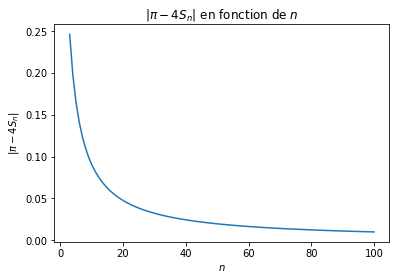

In [20]:
l = [(n,(Abs((pi-4*truncated_qa(n)))).evalf()) for n in range(3,101)]
# la fonction zip est bien adaptée pour la construction des couples: https://www.w3schools.com/python/ref_func_zip.asp
x,y=zip(*l)
plt.plot(x,y) # ou si l'on veut avoir les points non unis:
# plt.scatter(*zip(*l))
plt.title(r'$\left|\pi -4 S_n\right|$ en fonction de $n$')
plt.xlabel(r'$n$')
plt.ylabel(r'$\left|\pi -4 S_n\right|$')
plt.show()


**d)**
Vos implémentations des deux questions précédentes sont-elles optimales quand au nombre d'opérations effectuées ?



Je ne pense pas qu'elle soit optimale car j'ai utilisé la fonction Sum de sympy pour sa simplicité mais elle retourne une expression non évaluée, on peut voir que, par rapport à une fonction ad hoc, l'execution prend 7 fois plus de temps avec Sum. L'avantage de Sum c'est que l'on voit tout de suite de quoi il s'agit en changeant Sum par capital sigma. Par ailleurs, d'après https://en.wikipedia.org/wiki/Leibniz_formula_for_%CF%80, la convergence de la série altérnée de Leibniz est extremement lente, pouvant cette dernière être améliorée en appliquant les méthodes d'acceleration de la convergeance pour les séries alternées.

# Exercice 2: Séquençage de l'ADN

Le séquençage de l'ADN (une chaîne de caractères) consiste à déterminer l'ordre d'enchaînement des nucléotides pour un fragment d'ADN donné.

**a)**
Etant donné un séquençage d'ADN (par exemple, `S = "ACCTG"`), créez un dictionnaire pour compter le nombre d'occurrences de `A`, de `C`, de `G` et de `T`.




**b)**
Lorsqu'une bactérie est atteinte par un virus, la réplication de l'ADN peut être affectée de manière aléatoire. Chaque nucléotide (`A`, `C`, `G` ou `T`) va selon une certaine probabilité être recopiée de la manière suivante:
Chaque `A` peut être répliqué comme 3 `A`, chaque `C` peut être répliqué comme 4 `C`, chaque `G` peut être
répliqué comme 4 `G`, et chaque `T` peut être répliqué comme 3 `T`.

Écrire une fonction `infect(S,D)` qui étant donné une séquence `S` d'ADN et un dictionnaire `D` donnant la probabilité de réplication de chaque nucléotides produira
aléatoirement une séquence infectée.
Par exemple, si `S = "ACCTG"` et `D = {'A':0.2,'C': 0.5,'G': 0.3,'T': 0.1}`, la première lettre
(un `A`) a 20% de chance d’être répliquée comme 3 `A`, la seconde (un `C`), 50% de chances de
devenir 4 `C`, etc.




**c)**
Dans la suite on appelle `A` et `B` deux séquences d'ADN de respectivement $m$ et $n$ nucléotides que l'on veut comparer.

Pour déterminer l'alignement de score maximal de `A` et `B`, et permettre de trouver la meilleure ressemblance parmi un ensemble de comparaisons, on peut utiliser l'algorithme de Needleman-Wunsch. Une matrice $F$ des similarités est utilisée et ses éléments aux positions $(i, j)$ sont notés $F_{i,j}$ pour $0 \leq i \leq m$ et $0 \leq j \leq n$ . Il y a une colonne pour chaque caractère de la séquence `B`, et une ligne pour chaque caractère de la séquence `A`.

Au fur et à mesure de la progression de l'algorithme, $F_{i,j}$ se verra affecter le score optimal pour l'alignement des $i$ premiers caractères de A avec les $j$ premiers caractères de B. L'algorithme se présente ainsi:

* Pour l'initalisation, une matrice $F$ avec $m+1$ lignes et $n+1$ colonnes indexée à partir de zéro est créée pour comparer des séquences `A` et `B` de respectivement $m$ et $n$ nucléotides. On initialise la première ligne et la première colonne avec des zéros.

* Pour chaque $i=\{1,...,m\}$ et chaque $j=\{1,...,n\}$, les valeurs de $F$ sont définies récursivement par

$$
F_{i,j}=\max\bigl(F_{i-1,j-1}+S_{i-1,j-1},F_{i-1,j}-1,F_{i,j-1}-1\bigr) \quad\text{où}\quad S_{i,j} = \begin{cases}
1 & \text{si }A_{i}=B_{j}\\ 
0 & \text{sinon}
\end{cases}.
$$

* Pour finir, le score maximal d'alignement est le maximum des coefficients de la matrice $F$, $d=\max_{i,j}(F_{ij})$.

Écrire une fonction `needleman_wunsch(A,B)` qui étant donné deux séquences d'ADN renvoie
le score maximal d'alignement entre ces deux chaînes.
Tester avec les séquences `A = "GAATTCAGTTA"` et `B = "GGATCGA"` pour lesquelles le score maximal d'alignement est 4.




**d)**
Ouvrir le fichier `adn.txt` en lecture. Soit `S = "CGTCCGGTTTCGATTGGAGGGCTCGGAA"` une séquence d'ADN suspectée responsable d'une mutation. Récupérez les 8 personnes dans le fichier ayant la plus forte similarité avec cette séquence, et afficher leurs taux de similarités, leurs noms et prénoms.

**Indication:**
Pour lire le fichier `adn.txt` utiliser la fonction `open` dont la documentation est disponible [ici](https://docs.python.org/fr/3/library/functions.html#open). Par exemple pour afficher toutes les lignes du fichier commencant par la lettre "A":

In [13]:
with open("adn.txt","r") as file:
    for ligne in file:
        if ligne[0]=="A": print(ligne)


**e)**
<span style="color:red">[bonus]</span> Pour deux séquences de tailles $n$ et $m$, quelle est la complexité de l'algorithme de Needleman-Wunsch?




<!-- --- end exercise --- -->




<!-- --- begin exercise --- -->

# Exercice 3: Calcul d'enveloppe convexe

Le but de l'exercice est d'implémenter un algorithme qui permet de calculer l'enveloppe convexe d'un ensemble fini $\mathcal{E}$ de points de $\mathbb{R}^2$.

On pourra représenter un point de $\mathbb{R}^{2}$ par un 2-`tuple` de flottants, un `complex`, ou toute structure qui paraîtra adaptée à l'exercice.
Un ensemble de points pourra être représenté par un `set` ou une liste de points, selon la structure choisie pour les points.
L'enveloppe convexe d'un ensemble de points pourra être représentée par une liste de points successifs qui permettent de la tracer. La figure suivante représente l'enveloppe convexe $[A,E,D,C]$ des points $\{A,B,C,D,E,F\}$:

<center>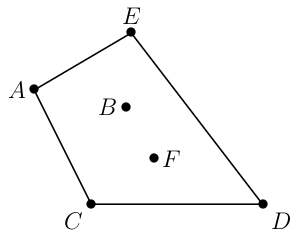</center>

Le but est d'implémenter l'algorithme de la marche de Jarvis.
L'idée est de construire la liste représentant l'enveloppe convexe successivement, en partant d'un point d'abscisse minimale (le point $A$ dans la figure).

**a)**
Écrire une fonction `premier_point(E)` qui étant donné un ensemble de point `E` renvoie un point d'abscisse minimale.




Les points suivants sont construits en "tournant" autour de l'ensemble $\mathcal{E}$ toujours dans le même sens.
Plus précisément, si $X$ est un point de l'enveloppe convexe et que $Y_1,Y_2\in \mathcal{E}$, on dit que $Y_1$ est **à gauche** de $Y_2$ pour le point $X$ si et seulement si l'angle orienté $\widehat{Y_2XY_1}$ est dans $[0,\pi]$.
Par exemple sur la figure, en considérant $X=A$, on a : $B$ est à gauche de $F$, qui est à gauche de $C$.
Pour $A$, le point *le plus à gauche* est $E$, qui est le second point de la liste qui donne l'enveloppe convexe.
En réitérant jusqu'à retomber sur $A$, on trouve l'enveloppe convexe en entier.

*On pourra supposer pour faire simple que trois points de l'ensemble $\mathcal{E}$ ne sont jamais alignés.*

**b)**
Écrire une fonction `gauche(X, Y1, Y2)` qui renvoie `True` si `Y1` est à gauche de `Y2` pour le point `X` (et renvoie `False` sinon). On ferra en sorte que `gauche(X, Y, X)` renvoie `True` et que `gauche(X, X, Y)` renvoie `False`.




**c)**
Écrire une fonction `prochain_point(E, X)` qui, étant donné un ensemble de points `E` et un point `X` renvoie le point `Y` le plus à gauche pour `X`.




**d)**
Écrire une fonction `enveloppe(E)` qui renvoie l'enveloppe convexe de l'ensemble `E`.




**e)**
En utilisant par exemple la fonction `scatter` de Matplotlib pour écrire une fonction permettant de représenter un ensemble de points et tracer son enveloppe convexe.   Tester avec un ensemble de $15$ points aléatoires dans $[0,1]^2$.

